In [1]:
# importing Necessary Lib..

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import math

import torch
import torch.nn as nn
import torch.optim as optim
import shap


from ydata_profiling import ProfileReport


In [2]:
# Importing Datas
df = pd.read_csv('loan_approval_dataset.csv')
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
# Learning About datasets
print("=="*30)
print(f"Total Number of Row and Features in Data : {df.shape}")
print()
print("=="*30)
print()
print()

print(df.info())

Total Number of Row and Features in Data : (4269, 13)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int

In [4]:
# Checking for NULL AND Duplicate Row
print(f" Duplicate rows {df.duplicated().sum()}") 
print()
print()
print("=="*30)
print(f"Totla Null values in DataFrame \n {df.isna().sum()}")

 Duplicate rows 0


Totla Null values in DataFrame 
 loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64


In [5]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [6]:
# Debug Block for labels
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

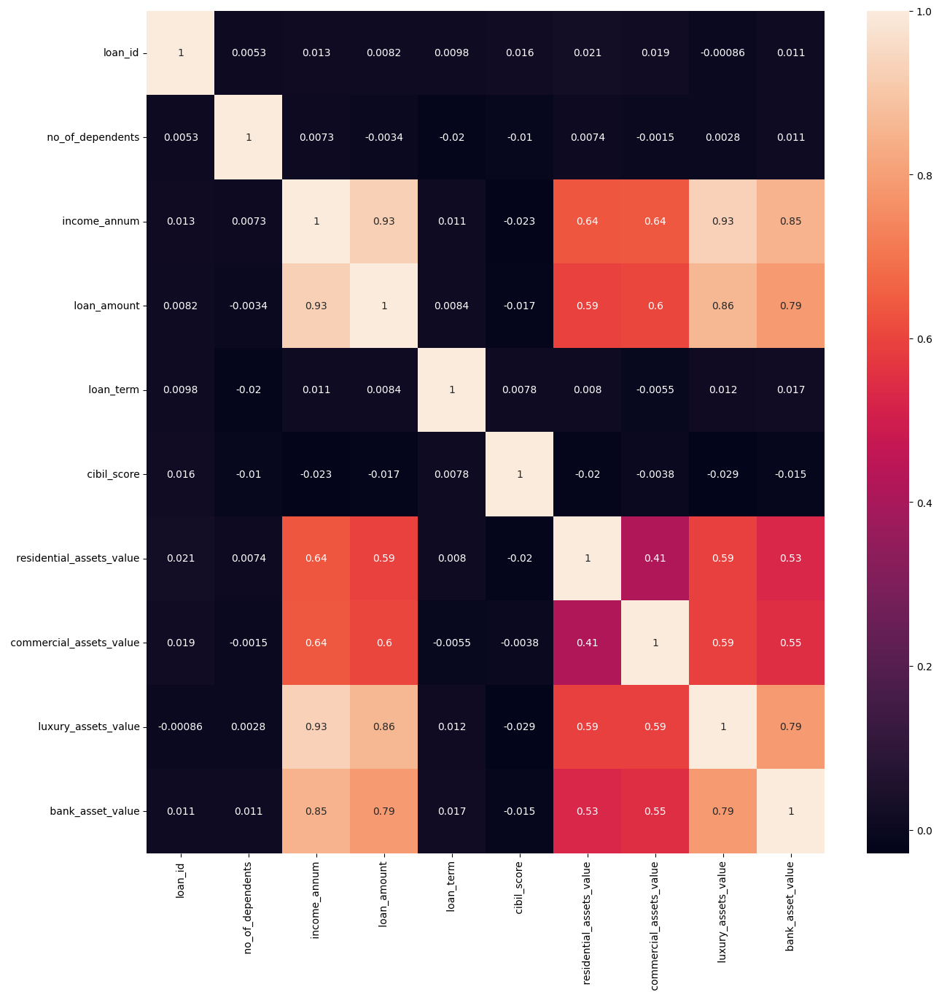

In [7]:
df_numeric = df.select_dtypes('int64')
df_numeric.head()

plt.figure(figsize=(15,15))
sns.heatmap(df_numeric.corr(),annot=True)
plt.show()

In [8]:
df.drop(columns='loan_id',inplace=True)

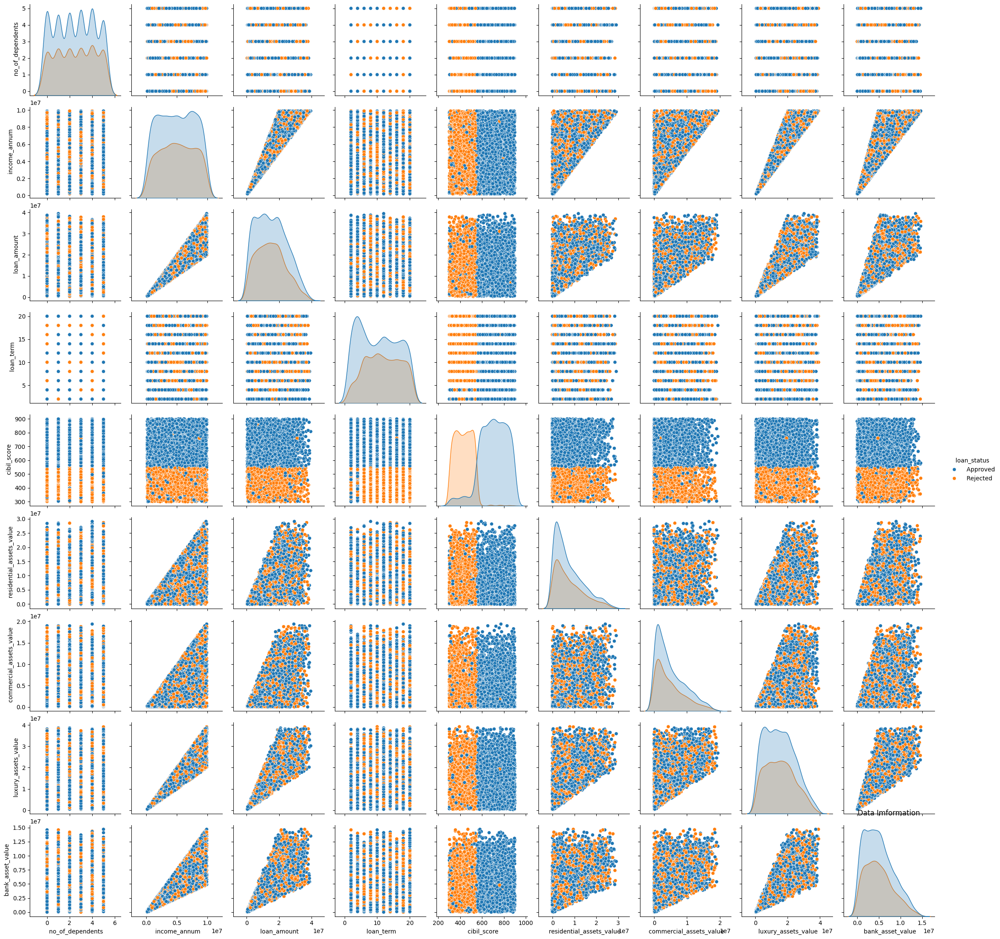

In [9]:
sns.pairplot(df,hue=' loan_status')
plt.title("Data Imformation")
plt.show()

In [10]:
report = ProfileReport(df)
report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████| 12/12 [00:00<00:00, 986.26it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [11]:
# SPlitting Train and Test
from sklearn.model_selection import train_test_split

x = df.drop(columns=' loan_status')
y = df[' loan_status']

In [12]:
print(f"Shape of X : {x.shape}")
print()
print(f"Shape of Y : {y.shape}")


Shape of X : (4269, 11)

Shape of Y : (4269,)


In [13]:
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42,test_size=0.2,shuffle=True)


In [14]:
print(f"Shape of X Train : {x_train.shape}")
print()
print(f"Shape of Y Train: {y_train.shape}")

Shape of X Train : (3415, 11)

Shape of Y Train: (3415,)


In [15]:
print(f"Shape of X Test : {x_test.shape}")
print()
print(f"Shape of Y Test : {y_test.shape}")

Shape of X Test : (854, 11)

Shape of Y Test : (854,)


In [16]:
print(df.select_dtypes('object').columns)

Index([' education', ' self_employed', ' loan_status'], dtype='object')


In [17]:
# Debug section
x_train.head()


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
1675,5,Not Graduate,No,7900000,29900000,6,568,5800000,13900000,15900000,8700000
1164,0,Not Graduate,Yes,9600000,34000000,12,710,23800000,10300000,38100000,7800000
192,1,Graduate,No,800000,2900000,8,682,2200000,1100000,2900000,700000
910,2,Graduate,Yes,4900000,13100000,18,754,8200000,3300000,16500000,7200000
567,5,Graduate,Yes,3000000,11100000,12,441,8500000,2500000,7300000,2000000


In [18]:
# Nor Normalizing and encodeing Datas
from sklearn.preprocessing import StandardScaler,LabelEncoder

education = LabelEncoder()
self_employee = LabelEncoder()
loan = LabelEncoder()

# ENCODING EDUCATION
x_train[' education'] = education.fit_transform(x_train[' education'])
x_test[' education'] = education.transform(x_test[' education'])


# ENCODING SELF EMPLOYEED
x_train[' self_employed'] = self_employee.fit_transform(x_train[' self_employed'])
x_test[' self_employed'] = self_employee.transform(x_test[' self_employed'])


# ENCODING LOAN STATUS

y_train = loan.fit_transform(y_train)
y_test = loan.transform(y_test)



scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


In [19]:
x_test = np.array(x_test)
x_train = np.array(x_train)

y_train = np.array(y_train)
y_test = np.array(y_test)

In [20]:
from torch.utils.data import DataLoader,Dataset


In [21]:
class CustomDataset(Dataset):
    def __init__(self,x,y):
        self.x = torch.tensor(x,dtype = torch.float32)
        self.y = torch.tensor(y,dtype = torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self,index):
        return self.x[index] , self.y[index]

    
        

In [22]:
test_dataset = CustomDataset(x_test,y_test)
train_dataset = CustomDataset(x_train,y_train)

In [23]:
# Batching Data
test_dataloader = DataLoader(test_dataset,batch_size=32,shuffle=False,pin_memory=True,drop_last=False) 
# prediction do not need randomess suffel in data so we dont need shuffel whilc just increase opertation cost

train_dataloader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True,drop_last=False)

In [24]:
for X, y in train_dataloader:
    
    print(X)
    print(y)
    print()
    print()
    print("Total Data in 1 Batch ",len(X))
    break

tensor([[ 1.5125,  1.0026, -1.0150, -0.6622, -0.6480, -0.8600,  0.3237, -0.0720,
         -0.4014, -0.2708, -0.2316],
        [ 0.9230,  1.0026, -1.0150, -0.2710,  0.1463, -1.2096, -0.3558,  0.4782,
          0.2622, -0.6415, -0.8811],
        [-1.4350, -0.9974, -1.0150, -0.3777, -0.4053, -0.5104, -0.9657, -0.4541,
         -0.4929, -0.7396,  0.2943],
        [-0.8455,  1.0026,  0.9852,  0.1914, -0.1626, -0.5104, -0.6346,  0.4018,
         -0.2870,  0.3615, -0.2316],
        [-0.2560,  1.0026,  0.9852, -1.1958, -1.2880,  1.5874,  0.5387, -0.8056,
         -0.8132, -1.1321, -1.0049],
        [-0.8455,  1.0026,  0.9852, -1.5159, -1.3652,  0.8882,  0.7303, -0.8362,
         -0.8361, -1.3174, -1.1595],
        [-1.4350,  1.0026, -1.0150, -1.1958, -1.0452,  0.1889, -1.0354, -0.6222,
         -0.8818, -0.9467, -1.2523],
        [ 0.3335,  1.0026, -1.0150, -0.3421, -0.1185, -0.1607, -1.7441,  0.0197,
         -0.6530, -0.7396, -0.8502],
        [-1.4350,  1.0026,  0.9852,  0.9739,  0.4222,  0

In [25]:
# Building a basic Archirecture 

class Simple_ANN(nn.Module):
    def __init__(self,features,total_classes):
        super().__init__()

        self.ann = nn.Sequential(nn.Linear(features, 128),
                                nn.ReLU(),
                                nn.Linear(128, 64),
                                nn.ReLU(),
                                nn.Linear(64, total_classes))


    def forward(self,x):
        return self.ann(x)
    
        

In [26]:
# INITIALIZING MODEL ,OPTIMIZER ,LOSS FUNCTION, LEARNING RATE, EPOCHS

# epochs and lr
epochs = 100
lr = 1e-4

# declaring model
model1 = Simple_ANN(x_train.shape[1],2)  #2 cause no of classes we have is 2 binary classification

# declaring loss function
citration = nn.CrossEntropyLoss()  #can use Binary Loss but we have chose 2 node as op node so Cross entropy

# declaring optimizer
optimizer = optim.Adam(model1.parameters(),lr=lr)


# retriving GPU to train model

device=('cuda' if torch.cuda.get_device_name() else 'cpu')

# print(device)

# Setting GPU as model copmutation
model1.to(device)

Simple_ANN(
  (ann): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

In [27]:
model1

Simple_ANN(
  (ann): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

In [28]:
train_losses = []
validation_losses = []

for epoch in range(epochs):
    model1.train()
    train_loss = 0

    for batch_data, batch_label in train_dataloader:
        batch_data = batch_data.to(device)
        batch_label = batch_label.to(device)

        # Forward
        y_pred = model1(batch_data)

        # Loss
        loss = citration(y_pred, batch_label)

        # Backprop
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_dataloader)
    train_losses.append(avg_train_loss)

    print(f"Epoch {epoch+1} Train Loss: {avg_train_loss}")

    #  Validation
    model1.eval()
    total_val_loss = 0

    with torch.no_grad():
        for batch_data, batch_label in test_dataloader:
            batch_data = batch_data.to(device)
            batch_label = batch_label.to(device)

            y_pred = model1(batch_data)
            loss = citration(y_pred, batch_label)

            total_val_loss += loss.item()

    avg_val_loss = total_val_loss / len(test_dataloader)
    validation_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1} Val Loss: {avg_val_loss}")
    print("="*50)

Epoch 1 Train Loss: 0.6396600074857195
Epoch 1 Val Loss: 0.5914523115864506
Epoch 2 Train Loss: 0.5347995487886055
Epoch 2 Val Loss: 0.46670924513428297
Epoch 3 Train Loss: 0.4035719240380225
Epoch 3 Val Loss: 0.3496848300651268
Epoch 4 Train Loss: 0.31016045182107765
Epoch 4 Val Loss: 0.2853313027708619
Epoch 5 Train Loss: 0.2634444480465951
Epoch 5 Val Loss: 0.25525553303736226
Epoch 6 Train Loss: 0.2386324924425544
Epoch 6 Val Loss: 0.24134335694489656
Epoch 7 Train Loss: 0.22608928445065132
Epoch 7 Val Loss: 0.22767704946023445
Epoch 8 Train Loss: 0.2158291249353195
Epoch 8 Val Loss: 0.22080353564686245
Epoch 9 Train Loss: 0.2083527074308596
Epoch 9 Val Loss: 0.21585248631459694
Epoch 10 Train Loss: 0.2025796949306381
Epoch 10 Val Loss: 0.2099611955108466
Epoch 11 Train Loss: 0.19726656286794447
Epoch 11 Val Loss: 0.20513056991276918
Epoch 12 Train Loss: 0.19278394594510026
Epoch 12 Val Loss: 0.20237505794675262
Epoch 13 Train Loss: 0.18871523603518434
Epoch 13 Val Loss: 0.19641360

In [30]:
# Debug slide
# for batch_data, batch_label in test_dataloader:
#     print(batch_label)
#     print()
#     print(batch_data)
#     break

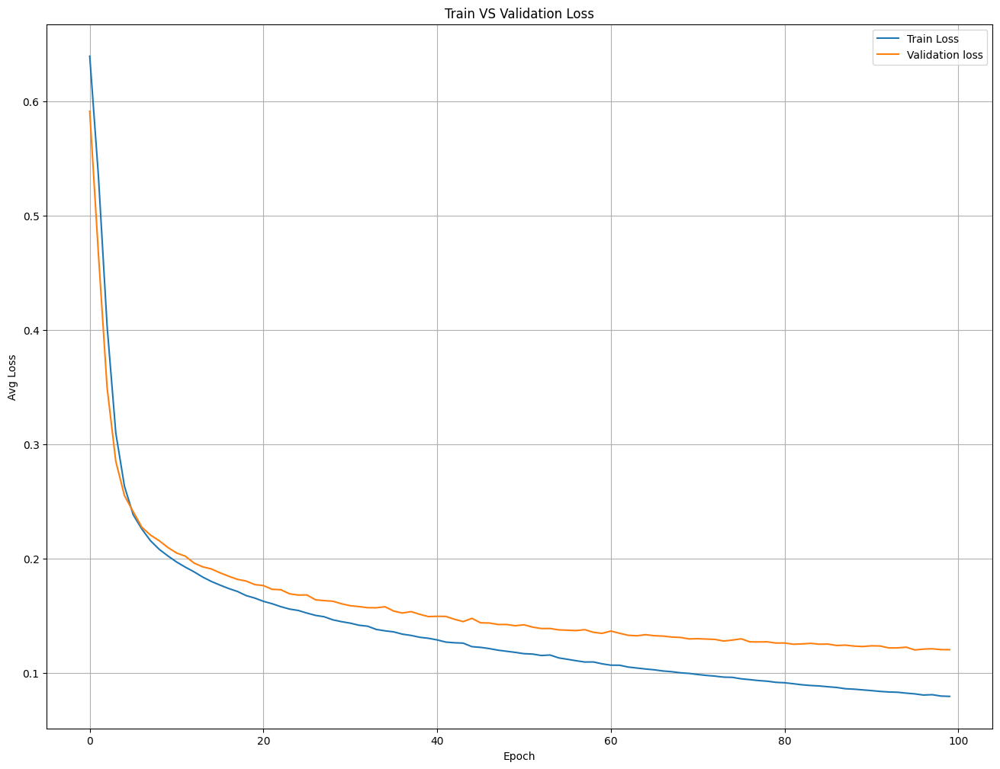

In [34]:
plt.figure(figsize=(16,12))
plt.plot(train_losses,label="Train Loss")
plt.plot(validation_losses,label="Validation loss")
plt.title("Train VS Validation Loss")
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Avg Loss")
plt.legend()
plt.show()

# Small Overfit can be solved using ANN Optimization Dropout Requlizer,Batch Norm...

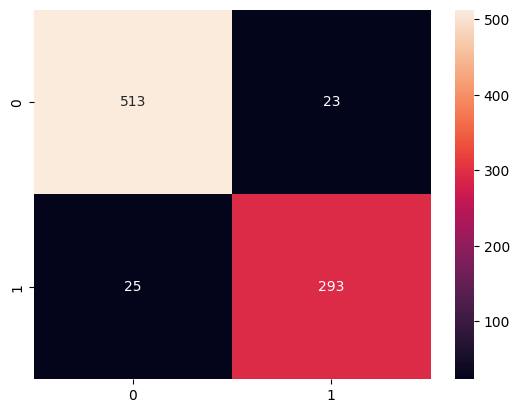

In [43]:
from sklearn.metrics import confusion_matrix

all_preds = []
all_labels = []

model1.eval()

with torch.no_grad():
    for X, y in test_dataloader:
        X = X.to(device)
        y = y.to(device)

        outputs = model1(X)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        prob = torch.softmax(outputs, dim=1)[:,1]
        # probs.extend(prob.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

sns.heatmap(cm,annot=True,fmt='d')
plt.show()

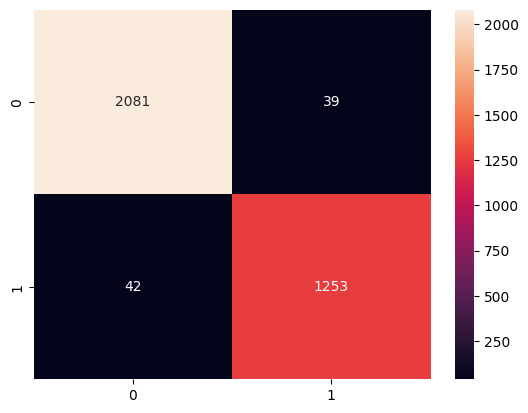

In [44]:

all_preds = []
all_labels = []

model1.eval()

with torch.no_grad():
    for X, y in train_dataloader:
        X = X.to(device)
        y = y.to(device)

        outputs = model1(X)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        prob = torch.softmax(outputs, dim=1)[:,1]
        # probs.extend(prob.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

sns.heatmap(cm,annot=True,fmt='d')
plt.show()

In [ ]:

all_preds = []
all_labels = []

model1.eval()

with torch.no_grad():
    for X, y in test_dataloader:
        X = X.to(device)
        y = y.to(device)

        outputs = model1(X)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        prob = torch.softmax(outputs, dim=1)[:,1]
        # probs.extend(prob.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

sns.heatmap(cm,annot=True,fmt='d')
plt.show()